# 03 — A címkék ellenőrzése / Validating the labels

HU: Valódi címke hiányában öt bizonyítékot gyűjtünk arról, hogy a BERT-címkék megbízhatóak:

| # | Bizonyíték / Evidence | Mit mutat? / What does it show? |
|---|---|---|
| 1 | Eloszlások / Distributions | mennyire térnek el a források / how the sources differ |
| 2 | Egyezés (kappa) / Agreement | a három megközelítés konzisztenciája / consistency of the three |
| 3 | Vendégpontszám / Guest score | konvergens validitás / convergent validity |
| 4 | Mezőpróba, HRAST-teszt / Field test, HRAST test | független ellenőrzés / independent checks |
| 5 | **Kézi gold minta / Manual gold sample** | **közvetlen pontosság / direct accuracy** |

Ez a notebook CPU-n, helyben fut (a 02 mentett eredményeiből). / Runs locally on a CPU (from the saved outputs of 02).

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import label_validation as lv
from src import pipeline

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

data = dl.read_frame(pipeline.LABELLED).set_index("review_id")
data["score_cut_label"] = lv.score_cut_labels(data["score"])     # HU/EN: REFERENCE ONLY
approaches = lv.available_approaches(data)
SOURCES = {**{f"{a}": f"{a}_label" for a in approaches}, "final": "label_final",
           "score cut (reference)": "score_cut_label"}
print(f"{len(data):,} reviews | approaches: {approaches}")

20,000 reviews | approaches: ['A', 'B', 'C']


## 1. Eloszlások / Distributions

,negative,neutral,positive,n
A,0.0341,0.0381,0.9278,20000
B,0.0560,0.1539,0.7900,20000
C,0.0238,0.3478,0.6284,20000
final,0.0560,0.1539,0.7900,20000
score cut (reference),0.1289,0.2262,0.6450,20000


13:14:23 | INFO    | src.evaluation | Table saved: 03_label_distribution.csv
13:14:23 | INFO    | src.evaluation | Figure saved: 03_label_distribution.png


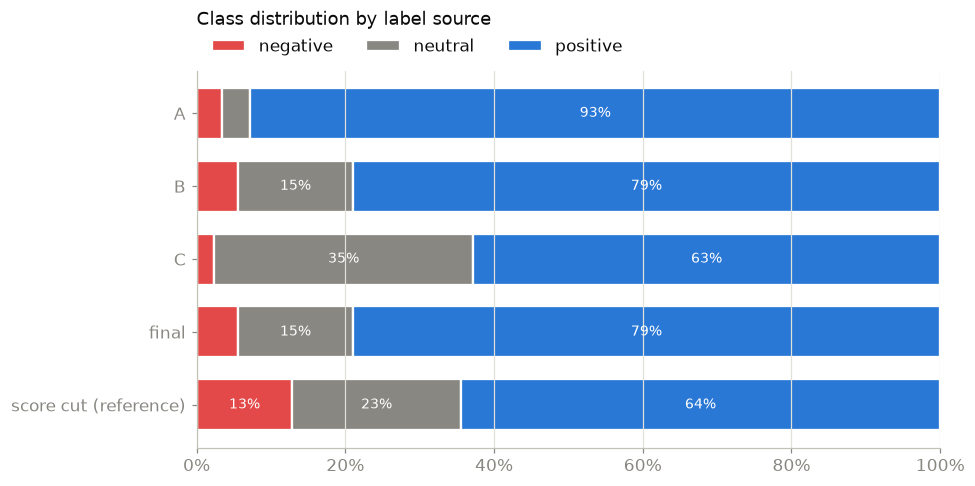

In [2]:
dist = lv.label_distribution(data, SOURCES)
display(dist)
ev.save_table(dist, "03_label_distribution")
lv.plot_label_distribution(dist, title="Class distribution by label source", save_as="03_label_distribution")
plt.show()

## 2. Egyezés a megközelítések között / Agreement between the approaches

HU: A (C) a saját tanítóvéleményein a tanárokat "visszamondja", ezért azokat kizárjuk (`comparison_mask`).
EN: On its own training reviews (C) "repeats" the teachers, so those are excluded (`comparison_mask`).

In [3]:
mask = lv.comparison_mask(data)
print(f"Rows used for agreement: {mask.sum():,} of {len(data):,}")
agreement = lv.pairwise_agreement(data[mask], SOURCES)
display(agreement)
ev.save_table(agreement, "03_pairwise_agreement")
fk = lv.fleiss_kappa(data[mask], [f"{a}_label" for a in approaches])
print(f"Fleiss' kappa ({', '.join(approaches)}): {fk:.3f}")

Rows used for agreement: 10,331 of 20,000


,n,agreement,cohen_kappa,weighted_kappa
pair,,,,
A vs B,10331,0.7670,0.2508,0.3420
A vs C,10331,0.4551,0.0706,0.1147
A vs final,10331,0.7670,0.2508,0.3420
A vs score cut (reference),10331,0.5906,0.1123,0.1511
B vs C,10331,0.5961,0.3080,0.3553
B vs final,10331,1.0000,1.0000,1.0000
B vs score cut (reference),10331,0.5941,0.2193,0.2929
C vs final,10331,0.5961,0.3080,0.3553
C vs score cut (reference),10331,0.5133,0.1995,0.2576


13:14:24 | INFO    | src.evaluation | Table saved: 03_pairwise_agreement.csv


Fleiss' kappa (A, B, C): 0.122


13:14:24 | INFO    | src.evaluation | Table saved: 03_crosstab_A_label_vs_B_label.csv
13:14:25 | INFO    | src.evaluation | Figure saved: 03_crosstab_A_label_vs_B_label.png


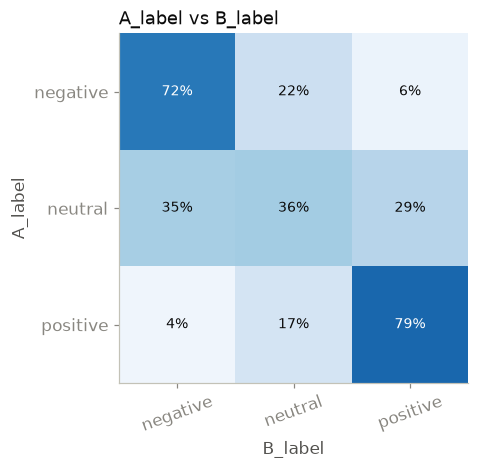

13:14:25 | INFO    | src.evaluation | Table saved: 03_crosstab_A_label_vs_C_label.csv
13:14:25 | INFO    | src.evaluation | Figure saved: 03_crosstab_A_label_vs_C_label.png


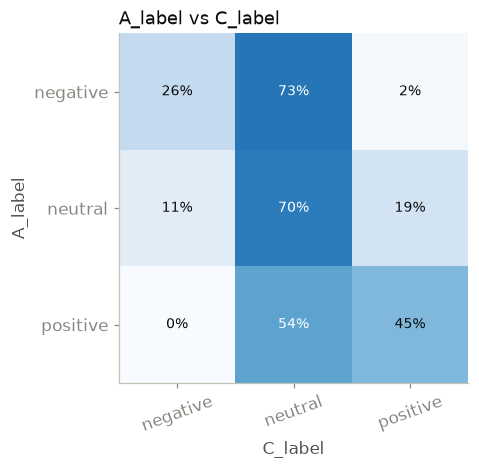

13:14:26 | INFO    | src.evaluation | Table saved: 03_crosstab_label_final_vs_score_cut_label.csv
13:14:26 | INFO    | src.evaluation | Figure saved: 03_crosstab_label_final_vs_score_cut_label.png


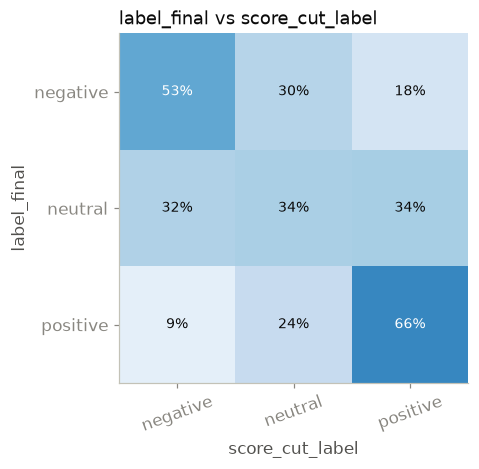

In [4]:
pairs = [("A_label", "B_label"), ("A_label", "C_label"), ("label_final", "score_cut_label")]
for col_a, col_b in pairs:
    if {col_a, col_b} <= set(data.columns):
        tab = lv.approach_crosstab(data[mask], col_a, col_b)
        name = f"03_crosstab_{col_a}_vs_{col_b}"
        ev.save_table(tab, name)
        lv.plot_agreement_matrix(tab, f"{col_a} vs {col_b}", xlabel=col_b, ylabel=col_a, save_as=name)
        plt.show()

## 3. Kapcsolat a vendégpontszámmal / Relation to the guest score

HU: Erős, de **nem tökéletes** kapcsolat a jó eredmény. A `neg_but_score_ge9` oszlop mutatja, hányszor panaszkodik a
szöveg magas pontszám mellett — ezt a pontszám-vágás nem látná.
EN: A strong but **imperfect** relation is the good outcome. `neg_but_score_ge9` shows how often the text complains
despite a high score — a score cut would miss this.

,spearman_rho,mean_guest_score_negative,mean_guest_score_neutral,mean_guest_score_positive,neg_but_score_ge9,pos_but_score_le6
approach,,,,,,
A,0.5633,7.2243,8.0446,8.9707,0.0046,0.0167
B,0.4299,7.4674,8.0789,9.1311,0.0105,0.0070
C,0.4742,7.4591,8.2664,9.2670,0.0046,0.0035
final,0.4299,7.4674,8.0789,9.1311,0.0105,0.0070


13:14:26 | INFO    | src.evaluation | Table saved: 03_guest_score_validity.csv
13:14:27 | INFO    | src.evaluation | Figure saved: 03_text_score_vs_guest_score.png


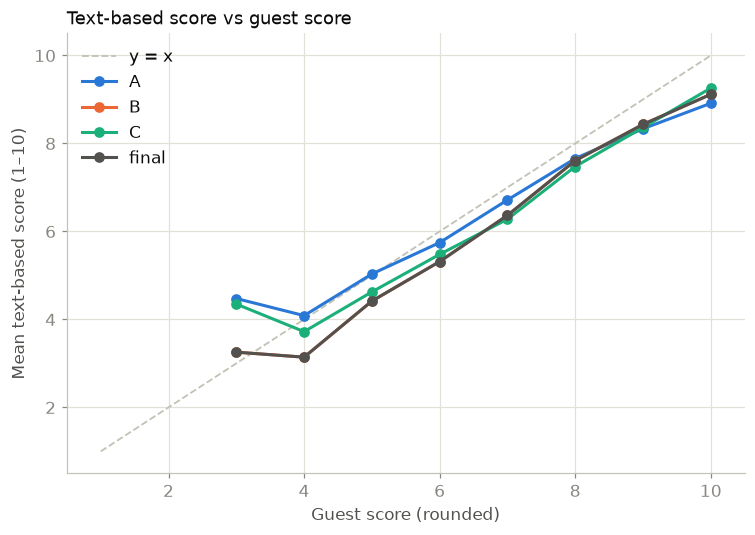

In [5]:
# HU: A végső címkét is "megközelítésként" kezeljük. / EN: The final label is treated as an "approach" too.
data["final_label"], data["final_score_cont"] = data["label_final"], data["score_cont_final"]
validity = lv.guest_score_validity(data, approaches + ["final"])
display(validity)
ev.save_table(validity, "03_guest_score_validity")
lv.plot_score_vs_guest(data, approaches + ["final"], save_as="03_text_score_vs_guest_score")
plt.show()

13:14:28 | INFO    | src.evaluation | Figure saved: 03_text_score_vs_guest_score.png


<Axes: title={'left': 'Text-based score vs guest score'}, xlabel='Guest score (rounded)', ylabel='Mean text-based score (1–10)'>

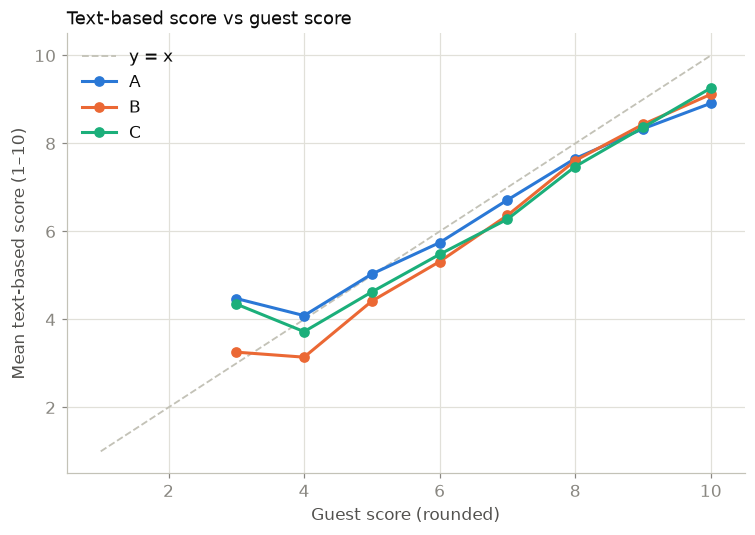

In [6]:
lv.plot_score_vs_guest(data, approaches, save_as="03_text_score_vs_guest_score")

In [7]:
# HU: Ahol a szöveg és a pontszám nagyon eltér — olvasd el, és válassz idézeteket a dolgozatba.
# EN: Where text and score differ strongly — read them and pick quotes for the thesis.
disc = lv.text_score_discrepancies(data.reset_index(), min_gap=4, n_examples=12)
ev.save_table(disc, "03_text_score_discrepancies")
for _, r in disc.iterrows():
    print(f"[guest {r['score']:.0f} | text {r['score10_final']} | {r['label_final']}]  {r['text'][:230]}\n")

13:14:28 | INFO    | src.label_validation | Reviews with |text score − guest score| ≥ 4: 1411 (7.05%)


13:14:28 | INFO    | src.evaluation | Table saved: 03_text_score_discrepancies.csv


[guest 10 | text 6 | neutral]  We will most likely stay at another La Quinta by Wyndham. We found the place very clean & well air conditioned. We did not find anything we didn’t like.

[guest 10 | text 6 | neutral]  Great price great area one block from boardwalk & Tramcar. Can’t beat the price. Great for kids it’s a “U” shape motel with pool in the middle so your kids are always in sight if you’re enjoying drinks in front of your room door c

[guest 10 | text 6 | neutral]  Value for money. Cheap and close to airport, bus station and many cafe also having 7Eleven For my room, I dont like that my double room didnt have desk. It make me put our things and stuff on the floor

[guest 10 | text 1 | negative]  - staff very friendfull, helpfull and very kind - the entire hotel and rooms was clean - good and consistent breakfast - EXCELENT LOCATION - 2 min walk to Blue Mosque or Hagia Sophia - the roof terrace is awesome - view to both mo

[guest 10 | text 5 | neutral]  The location was good. 

## 4. Független próbák / Independent checks

In [8]:
for name in ["02_field_test", "02_approach_b_hrast_test"]:
    path = PATHS.tables / f"{name}.csv"
    if path.exists():
        print(f"=== {name} ===")
        display(pd.read_csv(path))
    else:
        print(f"{name}: not available (run notebook 02).")

=== 02_field_test ===


,approach,field,n,hit,neutral,opposite
0,A,review_negative,2000,0.4970,0.3450,0.1580
1,A,review_positive,2000,0.9475,0.0480,0.0045
2,C,review_negative,2000,0.6810,0.2125,0.1065
3,C,review_positive,2000,0.9460,0.0480,0.0060
4,B,review_negative,2000,0.7640,0.0995,0.1365
5,B,review_positive,2000,0.9780,0.0065,0.0155


=== 02_approach_b_hrast_test ===


,Unnamed: 0,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,HRAST test,0.9414,0.7731,0.7825,0.7776,0.9431,0.9414,0.9422


## 5. Kézi gold minta / Manual gold sample

HU: Az **egyetlen közvetlen pontosságmérés**. Lépések:
1. az alábbi cella exportálja a `data/annotation/gold_sample_to_annotate.csv` fájlt (csak szöveg — **vak** annotálás);
2. töltsd ki a `gold_label` (negative / neutral / positive) és a `gold_score` (1–10) oszlopot a `docs/ANNOTATION_GUIDE.md` szerint;
3. futtasd újra a cellát → összevetés minden forrással, a **pontszám-vágással együtt**.

EN: The **only direct accuracy measurement**. Export → annotate blind (`docs/ANNOTATION_GUIDE.md`) → re-run → comparison
with every source, **including the score cut**.

In [10]:
#from src import label_validation as lv
#lv.gold_csv_to_xlsx()

In [ ]:
gold_file = PATHS.annotation / "gold_sample_to_annotate.csv"
if not gold_file.exists():
    lv.export_gold_sample(data.reset_index())
    print("Exported. Annotate it, then re-run this cell.")
else:
    gold = lv.load_gold()
    if len(gold) == 0:
        print("The gold file exists but has no valid gold_label yet.")
    else:
        score_cols = {**{a: f"{a}_score_cont" for a in approaches}, "final": "score_cont_final",
                      "score cut (reference)": "score"}
        gold_eval = lv.evaluate_on_gold(gold, data, SOURCES, score_cols)
        display(gold_eval)
        ev.save_table(gold_eval, "03_gold_evaluation")
        print("=> Set CFG.tie_breaker_approach in config.py to the best approach.")

12:55:53 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
12:55:53 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
12:55:53 | INFO    | src.label_validation | Gold reviews matched with labels: 399


,n,accuracy,f1_macro,cohen_kappa,score_mae
source,,,,,
B,399,0.8020,0.6312,0.5069,1.0497
final,399,0.8020,0.6312,0.5069,1.0497
score cut (reference),399,0.7168,0.5615,0.3797,1.3810
A,399,0.8045,0.5494,0.3369,1.1611
C,399,0.7318,0.5351,0.4234,1.1858


12:55:53 | INFO    | src.evaluation | Table saved: 03_gold_evaluation.csv


=> Set CFG.tie_breaker_approach in config.py to the best approach.


12:50:39 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
12:50:39 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
12:50:39 | INFO    | src.bert_labelling | (B) neutral band ±0.00 -> {'positive': 0.91, 'negative': 0.09}
12:50:39 | INFO    | src.bert_labelling | (B) neutral band ±0.10 -> {'positive': 0.832, 'neutral': 0.088, 'negative': 0.08}
12:50:39 | INFO    | src.bert_labelling | (B) neutral band ±0.15 -> {'positive': 0.807, 'neutral': 0.12, 'negative': 0.073}
12:50:39 | INFO    | src.bert_labelling | (B) neutral band ±0.20 -> {'positive': 0.787, 'neutral': 0.153, 'negative': 0.06}
12:50:39 | INFO    | src.bert_labelling | (B) neutral band ±0.25 -> {'positive': 0.764, 'neutral': 0.178, 'negative': 0.058}
12:50:39 | INFO    | src.bert_labelling | (B) neutral band ±0.30 -> {'positive': 0.752, 'neutral': 0.203, 'negative': 0.045}
12:50:39 | INFO    | src.bert_labelling | (B) neutral band ±0.35 -> {'positive': 0.674

,accuracy,f1_macro,cohen_kappa,f1_neutral,share_neutral
band,,,,,
0.00,0.8145,0.5292,0.4002,0.0000,0.0000
0.10,0.8095,0.6134,0.4638,0.2947,0.0877
0.15,0.8095,0.6326,0.4850,0.3519,0.1203
0.20,0.8095,0.6391,0.5004,0.4132,0.1529
0.25,0.8045,0.6405,0.5046,0.4427,0.1779
0.30,0.8020,0.6312,0.5069,0.4681,0.2030
0.35,0.7594,0.5786,0.4622,0.4746,0.2932
0.40,0.7569,0.5824,0.4691,0.4891,0.3108
0.50,0.7218,0.5478,0.4296,0.4757,0.3659


12:50:39 | INFO    | src.evaluation | Table saved: 03_neutral_band_calibration.csv


,f1_macro_low,f1_macro_high,accuracy_low,accuracy_high
source,,,,
A,0.4760,0.6146,0.7644,0.8446
B,0.5616,0.6987,0.7619,0.8421
C,0.4671,0.6037,0.6867,0.7744
final,0.5625,0.6960,0.7644,0.8371
score cut (reference),0.5002,0.6239,0.6717,0.7619


12:52:00 | INFO    | src.evaluation | Table saved: 03_gold_bootstrap_ci.csv


,precision,recall,f1-score,support
negative,0.833,0.375,0.517,40.000
neutral,0.407,0.550,0.468,60.000
positive,0.907,0.910,0.908,299.000
accuracy,0.802,0.802,0.802,0.802
macro avg,0.716,0.612,0.631,399.000
weighted avg,0.824,0.802,0.803,399.000


12:52:01 | INFO    | src.evaluation | Figure saved: 03_B_vs_gold_confusion.png


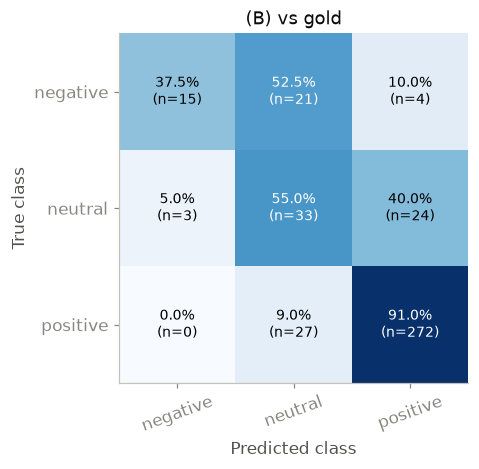

In [ ]:
from src import bert_labelling as bl

labels_b = bl.load_labels("labels_B")
gold = lv.load_gold()

# 1) HU: Semleges sáv kalibrálása / EN: Neutral band calibration
calib = lv.calibrate_neutral_band(gold, labels_b, "B")
display(calib); ev.save_table(calib, "03_neutral_band_calibration")

# 2) HU: 95%-os bootstrap-intervallumok / EN: 95% bootstrap intervals
ci = lv.bootstrap_ci(gold, data, SOURCES)
display(ci); ev.save_table(ci, "03_gold_bootstrap_ci")

# 3) HU: Hol hibázik a (B)? / EN: Where does (B) make mistakes?
joined = gold.join(data, how="inner", rsuffix="_lbl")
display(ev.per_class_report(joined["gold_label"], joined["B_label"]).round(3))
ev.plot_confusion_matrix(joined["gold_label"], joined["B_label"], title="(B) vs gold",
                         save_as="03_B_vs_gold_confusion"); plt.show()

In [ ]:
   from src import pipeline
   from src.config import CFG
   labels_b = bl.apply_neutral_band(bl.load_labels("labels_B"), "B", CFG.review_neutral_band)
   bl.save_labels(labels_b, "labels_B")
   labelled = pipeline.step_combine()

12:53:02 | INFO    | src.bert_labelling | (B) neutral band ±0.25 -> {'positive': 0.79, 'neutral': 0.154, 'negative': 0.056}


12:53:02 | INFO    | src.bert_labelling | Labels saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\labels\labels_B.parquet (20000 rows)
12:53:02 | INFO    | src.bert_labelling | Combining approaches: ['B'] (tie-breaker: B)
12:53:21 | INFO    | src.bert_labelling | Labels saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\labels\labels_final.parquet (20000 rows)
12:53:22 | INFO    | src.pipeline | Final label distribution: {'positive': 0.79, 'neutral': 0.154, 'negative': 0.056}


In [12]:
from src import bert_labelling as bl, pipeline

# HU: Többségi szavazás (A+B+C) számolása CSAK összehasonlításra, mentés nélkül.
# EN: Majority vote (A+B+C) computed ONLY for comparison, without saving.
vote = bl.combine_approaches(pipeline._load_available_labels(),
                             approaches=("A", "B", "C"), tie_breaker="B")
data["vote_label"] = vote["label_final"]
data["vote_score_cont"] = vote["score_cont_final"]

sources = {**SOURCES, "vote A+B+C": "vote_label"}
score_cols = {**{a: f"{a}_score_cont" for a in approaches},
              "vote A+B+C": "vote_score_cont", "score cut (reference)": "score"}
cmp = lv.evaluate_on_gold(lv.load_gold(), data, sources, score_cols)
display(cmp); ev.save_table(cmp, "03_gold_B_vs_vote")
print(f"B and the vote agree on {(data['B_label'] == data['vote_label']).mean():.1%} of the reviews")

score_cols = {**{a: f"{a}_score_cont" for a in approaches}, "final": "score_cont_final",
              "vote A+B+C": "vote_score_cont", "score cut (reference)": "score"}

13:19:39 | INFO    | src.bert_labelling | Combining approaches: ['A', 'B', 'C'] (tie-breaker: B)
13:20:03 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
13:20:03 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
13:20:03 | INFO    | src.label_validation | Gold reviews matched with labels: 399


,n,accuracy,f1_macro,cohen_kappa,score_mae
source,,,,,
B,399,0.8045,0.6405,0.5046,1.0497
final,399,0.8045,0.6405,0.5046,NaN
vote A+B+C,399,0.8045,0.6403,0.4988,0.9956
score cut (reference),399,0.7168,0.5615,0.3797,1.3810
A,399,0.8045,0.5494,0.3369,1.1611
C,399,0.7318,0.5351,0.4234,1.1858


13:20:03 | INFO    | src.evaluation | Table saved: 03_gold_B_vs_vote.csv


B and the vote agree on 98.6% of the reviews


In [11]:
data["B_label"].value_counts(normalize=True).round(3)

B_label
positive    0.790
neutral     0.154
negative    0.056
Name: proportion, dtype: float64